# F.A.K.E.D. — Deepfake Detection **and** Manipulated-Region Segmentation review 2

Multi-task CNN on **FaceForensics++ (C23)**: one shared encoder feeding two heads —

| Head | Task | Output |
|---|---|---|
| Classification | Real vs. Fake | 2 logits |
| Segmentation | *Where* the face was manipulated | 1-channel mask, same size as input |

Both heads are trained together, so the localisation signal shapes the features the classifier uses.
Methodology follows Nguyen et al., *Multi-task Learning for Detecting and Segmenting Manipulated
Facial Images and Videos* (BTAS 2019, arXiv:1906.06876) — see the accompanying references document.

**Run profile:** single Kaggle T4, ~45 min end to end.

## 1. Setup

Imports, seeds, device. Everything downstream depends only on this cell.

In [2]:
import os, sys, time, random, re, gc, json, math, warnings
from pathlib import Path
from collections import defaultdict
warnings.filterwarnings("ignore")

NOTEBOOK_START = time.time()
elapsed = lambda: time.time() - NOTEBOOK_START
def hms(s):
    s = max(0, int(s))
    return f"{s//3600:02d}:{(s%3600)//60:02d}:{s%60:02d}"

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report,
                             balanced_accuracy_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

IN_KAGGLE = Path("/kaggle").exists()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

def amp_ctx():
    return torch.autocast(device_type=DEVICE.type, enabled=USE_AMP)

print(f"torch {torch.__version__} | device: {DEVICE} | AMP: {USE_AMP}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

torch 2.10.0+cu128 | device: cuda | AMP: True
GPU: Tesla T4


## 2. Configuration

Every number that controls runtime or accuracy lives here.

The values below are sized for a **~45 minute** T4 session: ~10 min preprocessing,
~20 min training, ~5 min evaluation, with a safety margin.

Two learning rates are deliberate. The encoder starts from ImageNet weights and only needs
gentle adaptation (`LR_ENCODER = 1e-4`); the decoder and heads are randomly initialised and
need a much larger step (`LR_HEAD = 1e-3`). Using one large LR for both is the fastest way
to destroy a pretrained backbone.

In [3]:
# ------------------------------- PATHS ---------------------------------
CANDIDATE_DATA_ROOTS = [Path("/kaggle/input/datasets/xdxd003"), Path("/kaggle/input")]

def find_data_root():
    for root in CANDIDATE_DATA_ROOTS:
        if not root.exists():
            continue
        if (root / "original").exists():
            return root
        for p in root.glob("**/original"):
            return p.parent
    return CANDIDATE_DATA_ROOTS[0]

DATA_ROOT = find_data_root()
WORK_ROOT = Path("/kaggle/working") if IN_KAGGLE else Path("./working")
FACE_ROOT, MASK_ROOT = WORK_ROOT / "faces", WORK_ROOT / "masks"
CKPT_DIR, PLOT_DIR = WORK_ROOT / "checkpoints", WORK_ROOT / "plots"
for d in (FACE_ROOT / "real", FACE_ROOT / "fake", MASK_ROOT, CKPT_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)

REAL_METHOD = "original"
FAKE_METHODS_KNOWN = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures",
                      "FaceShifter", "DeepFakeDetection"]

# ---------------------------- DATA SCALE -------------------------------
N_SOURCE_VIDEOS  = 400    # real videos; each paired with ONE fake variant -> 1:1 classes
FRAMES_PER_VIDEO = 12     # -> ~9,600 crops
MAX_FRAME_SCAN   = 200    # only decode the first N frames of each clip (keeps I/O cheap)
IMAGE_SIZE       = 224    # ImageNet-native resolution; 128 throws away the high-frequency
                          # artefacts that deepfake detection actually depends on

# ---------------------------- OPTIMISATION -----------------------------
BATCH_SIZE      = 32
EPOCHS          = 20
WARMUP_EPOCHS   = 1
LR_ENCODER      = 1e-4    # pretrained -> small steps
LR_HEAD         = 1e-3    # random init -> large steps
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.05
GRAD_CLIP       = 1.0
LEAKY_RELU_SLOPE = 0.01   # standard default; try 0.1–0.2 if you want a stronger effect

SEG_WEIGHT      = 0.5     # overall weight of the segmentation objective
DICE_WEIGHT     = 1.0     # weight of Dice within it (Dice runs on masked fakes only)

# ---------------------------- PREPROCESSING ----------------------------
FACE_PADDING      = 0.25
DETECTION_WIDTH   = 480
JPEG_QUALITY      = 95
MASK_MIN_DIFF     = 14     # grey levels; below this a "difference" is just re-compression noise
MASK_MIN_AREA     = 0.004  # reject masks covering <0.4% of the crop
MASK_MAX_AREA     = 0.65   # ...or >65% (means the frames were misaligned)

TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
NUM_WORKERS = 2 if IN_KAGGLE else 0

# ---------------------------- TIME BUDGET ------------------------------
TOTAL_TIME_BUDGET_SEC      = 55 * 60
PREPROCESS_TIME_BUDGET_SEC = 18 * 60
TRAIN_TIME_BUDGET_SEC      = 26 * 60
time_left = lambda: TOTAL_TIME_BUDGET_SEC - elapsed()

print(f"DATA_ROOT : {DATA_ROOT}")
print(f"WORK_ROOT : {WORK_ROOT}")
print(f"Target    : {N_SOURCE_VIDEOS} pairs x {FRAMES_PER_VIDEO} frames = "
      f"~{N_SOURCE_VIDEOS * FRAMES_PER_VIDEO * 2:,} crops at {IMAGE_SIZE}px")
print(f"Training  : {EPOCHS} epochs | LR enc/head = {LR_ENCODER}/{LR_HEAD}")

DATA_ROOT : /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23
WORK_ROOT : /kaggle/working
Target    : 400 pairs x 12 frames = ~9,600 crops at 224px
Training  : 20 epochs | LR enc/head = 0.0001/0.001


## 3. Index the dataset and pair real ↔ fake

FaceForensics++ stores one folder per manipulation method plus `original/`. Each fake filename
encodes the source video(s) it was derived from, so a fake can be matched back to its pristine
original.

For every sampled real video we take **exactly one** fake variant, cycling through the available
methods. That gives perfectly balanced classes and a fake set that still covers every
manipulation type.

In [4]:
assert DATA_ROOT.exists(), f"Dataset root not found: {DATA_ROOT}"
video_paths = sorted(DATA_ROOT.rglob("*.mp4"))
assert video_paths, f"No MP4 videos found under {DATA_ROOT}"

records = []
for vp in video_paths:
    method = vp.parent.name
    if method != REAL_METHOD and method not in FAKE_METHODS_KNOWN:
        continue
    ids = re.findall(r"\d+", vp.stem)
    records.append({
        "video_id": vp.stem,
        "video_path": str(vp),
        "label": 0 if method == REAL_METHOD else 1,
        "class_name": "real" if method == REAL_METHOD else "fake",
        "manipulation_method": method,
        "primary_source_id": ids[0] if ids else vp.stem,
    })

video_manifest = pd.DataFrame(records).drop_duplicates("video_path").reset_index(drop=True)
real_manifest = video_manifest[video_manifest.class_name == "real"].reset_index(drop=True)
fake_manifest = video_manifest[video_manifest.class_name == "fake"].reset_index(drop=True)
methods_available = sorted(fake_manifest.manipulation_method.unique())

print(f"Videos indexed: {len(video_manifest):,}  "
      f"(real {len(real_manifest):,} | fake {len(fake_manifest):,})")
print(f"Fake methods  : {methods_available}")

# ---- pair each real video with one fake derived from it ----
fake_lookup = defaultdict(dict)
for _, row in fake_manifest.iterrows():
    fake_lookup[row["primary_source_id"]][row["manipulation_method"]] = row

pairs, mi = [], 0
for _, r in real_manifest.sample(frac=1.0, random_state=SEED).iterrows():
    candidates = fake_lookup.get(r["primary_source_id"])
    if not candidates:
        continue
    chosen = None
    for _ in range(len(methods_available)):                 # round-robin over methods
        m = methods_available[mi % len(methods_available)]
        mi += 1
        if m in candidates:
            chosen = candidates[m]
            break
    chosen = chosen if chosen is not None else next(iter(candidates.values()))
    pairs.append({"video_id": r["video_id"], "real_row": r, "fake_row": chosen})
    if len(pairs) >= N_SOURCE_VIDEOS:
        break

assert pairs, "No real/fake pairs formed — check source-id parsing for this dataset mirror."
print(f"\nPaired {len(pairs)} videos (requested {N_SOURCE_VIDEOS}).")
print(pd.Series([p["fake_row"]["manipulation_method"] for p in pairs])
      .value_counts().to_string())

Videos indexed: 7,000  (real 1,000 | fake 6,000)
Fake methods  : ['DeepFakeDetection', 'Deepfakes', 'Face2Face', 'FaceShifter', 'FaceSwap', 'NeuralTextures']

Paired 400 videos (requested 400).
Deepfakes         80
Face2Face         80
FaceShifter       80
FaceSwap          80
NeuralTextures    80


## 4. Preprocessing — aligned crops and pseudo ground-truth masks

This is where the segmentation labels come from, and it is the part worth explaining to a reviewer.

**The alignment trick.** For each pair we take the *same frame index* from the real and the fake
video, detect the face **once on the real frame**, and crop **both** frames with that identical
box. The two crops are therefore pixel-aligned: they show the same person, pose, lighting and
background, and differ *only* where the manipulation was applied.

Two consequences:

1. `|real − fake|` localises the manipulation → a free pixel-level segmentation label.
2. The classifier cannot cheat on identity, background or pose, because both classes share them.
   It is forced to learn the manipulation artefact itself.

**Mask thresholding.** The naive version of this — Otsu's threshold on the difference image — is
what produced the useless masks in the earlier run. Otsu *always* splits a histogram into two
classes, so on a subtle manipulation where the only difference is codec noise it happily
labels random speckle as "manipulated". Fixes applied here:

- an **absolute floor** of `MASK_MIN_DIFF` grey levels, below which a difference is treated as noise;
- morphological open/close to remove speckle and fill the region;
- keep only the largest connected component (plus any component ≥30% of it);
- reject masks covering <0.4% or >65% of the crop.

A rejected mask does **not** discard the sample. The crops still train the classifier; the sample
is simply flagged `seg_valid = 0` and excluded from the segmentation loss and segmentation metrics.

In [5]:
face_cascade = cv2.CascadeClassifier(
    str(Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"))
assert not face_cascade.empty(), "OpenCV Haar cascade failed to load."


def frame_count_of(path):
    cap = cv2.VideoCapture(str(path))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if cap.isOpened() else 0
    cap.release()
    return n


def read_frames_at(path, indices):
    """Open the clip ONCE and pull all requested frames in a single sequential pass.
    grab() advances the decoder without the colour conversion, so skipped frames are cheap.
    (The old version re-opened the file and re-sought for every single frame.)"""
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        cap.release()
        return {}
    wanted = sorted({int(i) for i in indices})
    out, pos, w = {}, 0, 0
    while w < len(wanted):
        if not cap.grab():
            break
        if pos == wanted[w]:
            ok, frame = cap.retrieve()
            if ok:
                out[wanted[w]] = frame
            w += 1
        pos += 1
    cap.release()
    return out


def detect_face(frame):
    h, w = frame.shape[:2]
    scale = min(1.0, DETECTION_WIDTH / w)
    small = cv2.resize(frame, (max(1, int(w * scale)), max(1, int(h * scale))),
                       interpolation=cv2.INTER_AREA) if scale < 1.0 else frame
    gray = cv2.equalizeHist(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY))
    faces = face_cascade.detectMultiScale(gray, 1.1, 5, minSize=(30, 30))
    if len(faces) == 0:
        return None
    x, y, fw, fh = max(faces, key=lambda b: b[2] * b[3])
    inv = 1.0 / scale
    return int(x * inv), int(y * inv), int(fw * inv), int(fh * inv)


def padded_bounds(shape, box, padding=FACE_PADDING):
    x, y, w, h = box
    fh, fw = shape[:2]
    px, py = int(w * padding), int(h * padding)
    return (max(0, x - px), max(0, y - py), min(fw, x + w + px), min(fh, y + h + py))


def make_pseudo_mask(real_crop, fake_crop):
    """Pixel-level manipulation label from the aligned real/fake difference.
    Returns None when the difference is not a trustworthy localisation."""
    gray = cv2.cvtColor(cv2.absdiff(real_crop, fake_crop), cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)

    otsu_t, _ = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = ((gray >= max(MASK_MIN_DIFF, otsu_t)).astype(np.uint8)) * 255

    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8), iterations=2)

    n, lbl, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return None
    areas = stats[1:, cv2.CC_STAT_AREA]
    biggest = areas.max()
    keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= 0.30 * biggest]
    mask = (np.isin(lbl, keep).astype(np.uint8)) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))

    frac = float((mask > 0).mean())
    if not (MASK_MIN_AREA <= frac <= MASK_MAX_AREA):
        return None
    return mask


t0 = time.time()
frame_records, stats_counter = [], defaultdict(int)

for pair in tqdm(pairs, desc="Preprocessing pairs"):
    if time.time() - t0 > PREPROCESS_TIME_BUDGET_SEC:
        print(f"\nPreprocessing budget reached — stopping with "
              f"{stats_counter['crops']} crops.")
        break

    real_path = Path(pair["real_row"]["video_path"])
    fake_path = Path(pair["fake_row"]["video_path"])
    method = pair["fake_row"]["manipulation_method"]

    n_frames = min(frame_count_of(real_path), frame_count_of(fake_path), MAX_FRAME_SCAN)
    if n_frames <= 0:
        stats_counter["skipped_pairs"] += 1
        continue

    idxs = np.unique(np.linspace(0, n_frames - 1, FRAMES_PER_VIDEO, dtype=int)).tolist()
    real_frames = read_frames_at(real_path, idxs)
    fake_frames = read_frames_at(fake_path, idxs)

    last_box = None
    for i in idxs:
        rf, ff = real_frames.get(i), fake_frames.get(i)
        if rf is None or ff is None or rf.shape != ff.shape:
            continue

        box = detect_face(rf) or last_box
        if box is None:
            stats_counter["no_face"] += 1
            continue
        last_box = box                                  # reuse on detector misses

        x1, y1, x2, y2 = padded_bounds(rf.shape, box)
        if x2 - x1 < 32 or y2 - y1 < 32:
            continue

        real_crop = cv2.resize(rf[y1:y2, x1:x2], (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        fake_crop = cv2.resize(ff[y1:y2, x1:x2], (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)

        mask = make_pseudo_mask(real_crop, fake_crop)
        sid = f"{pair['video_id']}_{method}_{i:06d}"

        real_out = FACE_ROOT / "real" / f"{sid}.jpg"
        fake_out = FACE_ROOT / "fake" / f"{sid}.jpg"
        cv2.imwrite(str(real_out), real_crop, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
        cv2.imwrite(str(fake_out), fake_crop, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])

        if mask is not None:
            mask_out = MASK_ROOT / f"{sid}.png"
            cv2.imwrite(str(mask_out), mask)
            stats_counter["valid_masks"] += 1
        else:
            mask_out = None
            stats_counter["rejected_masks"] += 1

        common = {"sample_id": sid, "video_id": pair["video_id"], "manipulation_method": method}
        frame_records.append({**common, "clip_id": f"{pair['video_id']}__real",
                              "image_path": str(real_out), "mask_path": None,
                              "label": 0, "seg_valid": 0})
        frame_records.append({**common, "clip_id": f"{pair['video_id']}__fake",
                              "image_path": str(fake_out),
                              "mask_path": (str(mask_out) if mask_out else None),
                              "label": 1, "seg_valid": int(mask is not None)})
        stats_counter["crops"] += 2

assert stats_counter["crops"] > 0, "No crops produced — inspect dataset layout / detector."

frame_manifest = pd.DataFrame(frame_records)
frame_manifest.to_csv(WORK_ROOT / "frame_manifest.csv", index=False)

n_fake = int((frame_manifest.label == 1).sum())
print(f"\nPreprocessing: {hms(time.time() - t0)}")
print(f"Crops              : {len(frame_manifest):,} "
      f"(real {int((frame_manifest.label==0).sum()):,} | fake {n_fake:,})")
print(f"Usable seg. masks  : {stats_counter['valid_masks']:,} / {n_fake:,} fakes "
      f"({100*stats_counter['valid_masks']/max(1,n_fake):.1f}%)")
print(f"Rejected masks     : {stats_counter['rejected_masks']:,}   "
      f"detector misses: {stats_counter['no_face']}   skipped pairs: {stats_counter['skipped_pairs']}")
print(f"Elapsed            : {hms(elapsed())} / {hms(TOTAL_TIME_BUDGET_SEC)}")

Preprocessing pairs:   0%|          | 0/400 [00:00<?, ?it/s]


Preprocessing: 00:08:53
Crops              : 8,340 (real 4,170 | fake 4,170)
Usable seg. masks  : 4,079 / 4,170 fakes (97.8%)
Rejected masks     : 91   detector misses: 6   skipped pairs: 0
Elapsed            : 00:09:27 / 00:55:00


## 4b. Sanity-check the segmentation labels

Before training on these masks, look at them. A reviewer will ask where the ground truth came
from, and this cell is the answer: aligned pairs, the amplified difference, and the cleaned mask.

Healthy masks are compact and cover roughly the inner face — the area distribution should peak
somewhere in the 5–35% range, not at the extremes.

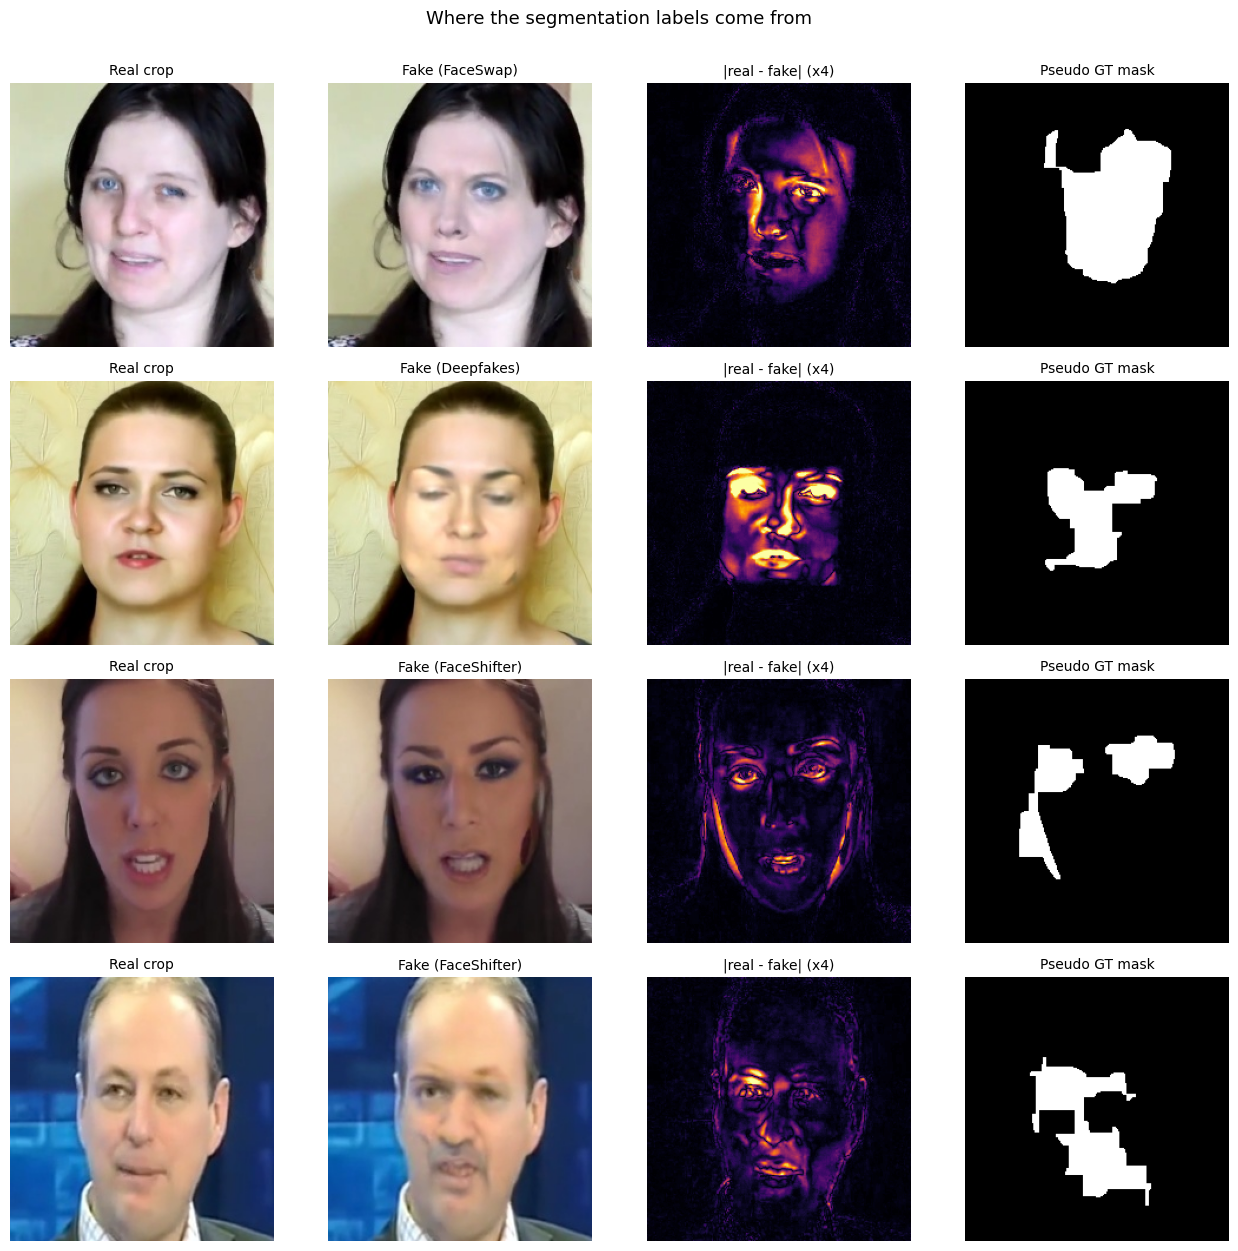

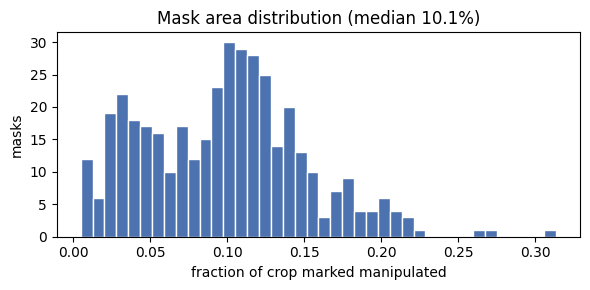

In [6]:
fakes_with_mask = frame_manifest[(frame_manifest.label == 1) & (frame_manifest.seg_valid == 1)]
assert len(fakes_with_mask), ("No usable pseudo-masks were produced. Lower MASK_MIN_DIFF or widen "
                              "MASK_MIN_AREA/MASK_MAX_AREA, then re-run preprocessing.")
show = fakes_with_mask.sample(n=min(4, len(fakes_with_mask)), random_state=SEED)

fig, axes = plt.subplots(len(show), 4, figsize=(13, 3.1 * len(show)))
axes = np.atleast_2d(axes)
for r, (_, row) in enumerate(show.iterrows()):
    fake = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    real = cv2.cvtColor(cv2.imread(row["image_path"].replace("/fake/", "/real/")), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    diff = cv2.cvtColor(cv2.applyColorMap(
        cv2.convertScaleAbs(cv2.absdiff(real, fake), alpha=4.0), cv2.COLORMAP_INFERNO),
        cv2.COLOR_BGR2RGB)
    for c, (im, ttl, kw) in enumerate([
            (real, "Real crop", {}), (fake, f"Fake ({row['manipulation_method']})", {}),
            (diff, "|real - fake| (x4)", {}), (mask, "Pseudo GT mask", {"cmap": "gray"})]):
        axes[r, c].imshow(im, **kw); axes[r, c].set_title(ttl, fontsize=10); axes[r, c].axis("off")
fig.suptitle("Where the segmentation labels come from", y=1.005, fontsize=13)
fig.tight_layout(); fig.savefig(PLOT_DIR / "mask_provenance.png", dpi=110, bbox_inches="tight")
plt.show()

areas = [float((cv2.imread(p, cv2.IMREAD_GRAYSCALE) > 127).mean())
         for p in fakes_with_mask["mask_path"].sample(
             n=min(400, len(fakes_with_mask)), random_state=SEED)]
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(areas, bins=40, color="#4C72B0", edgecolor="white")
ax.set_xlabel("fraction of crop marked manipulated"); ax.set_ylabel("masks")
ax.set_title(f"Mask area distribution (median {np.median(areas):.1%})")
fig.tight_layout(); fig.savefig(PLOT_DIR / "mask_area_hist.png", dpi=110); plt.show()

## 5. Splits, augmentation, loaders

**Splitting by source video, not by frame.** All crops derived from source video *N* — real and
fake — land in the same split. Splitting by frame would put near-identical frames of the same clip
in both train and test and inflate every number reported below.

Augmentation is deliberately mild and artefact-aware: horizontal flip, small random zoom,
brightness/contrast jitter, light blur, and **random JPEG re-compression**. The last one matters —
it stops the model from keying on this dataset's particular compression signature.
Geometric transforms are applied to the image and its mask identically.

In [7]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


class FacedDataset(Dataset):
    def __init__(self, df, train=False, size=IMAGE_SIZE):
        self.df = df.reset_index(drop=True)
        self.train, self.size = train, size

    def __len__(self):
        return len(self.df)

    def _augment(self, img, mask):
        if random.random() < 0.5:                                  # horizontal flip
            img, mask = cv2.flip(img, 1), cv2.flip(mask, 1)
        if random.random() < 0.4:                                  # random zoom-in
            s = random.uniform(0.85, 1.0)
            side = int(self.size * s)
            x = random.randint(0, self.size - side); y = random.randint(0, self.size - side)
            img = cv2.resize(img[y:y+side, x:x+side], (self.size, self.size), interpolation=cv2.INTER_LINEAR)
            mask = cv2.resize(mask[y:y+side, x:x+side], (self.size, self.size), interpolation=cv2.INTER_NEAREST)
        if random.random() < 0.5:                                  # brightness / contrast
            img = np.clip(img.astype(np.float32) * random.uniform(0.85, 1.15)
                          + random.uniform(-15, 15), 0, 255).astype(np.uint8)
        if random.random() < 0.2:                                  # mild blur
            img = cv2.GaussianBlur(img, (random.choice([3, 5]),) * 2, 0)
        if random.random() < 0.35:                                 # JPEG re-compression
            ok, enc = cv2.imencode(".jpg", img,
                                   [cv2.IMWRITE_JPEG_QUALITY, random.randint(45, 90)])
            if ok:
                img = cv2.imdecode(enc, cv2.IMREAD_COLOR)
        return img, mask

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = cv2.imread(row["image_path"])
        if img is None:
            img = np.zeros((self.size, self.size, 3), np.uint8)

        mp = row["mask_path"]
        if isinstance(mp, str) and mp:
            m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
            mask = (m > 127).astype(np.float32) if m is not None else np.zeros((self.size, self.size), np.float32)
        else:
            mask = np.zeros((self.size, self.size), np.float32)

        if self.train:
            img, mask = self._augment(img, mask)

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        img = (img - IMAGENET_MEAN) / IMAGENET_STD
        return (torch.from_numpy(img).permute(2, 0, 1).float(),
                torch.tensor(int(row["label"]), dtype=torch.long),
                torch.from_numpy(mask).unsqueeze(0).float(),
                torch.tensor(float(row["seg_valid"]), dtype=torch.float32))


# ---- group-aware split ----
vids = frame_manifest["video_id"].unique().tolist()
random.Random(SEED).shuffle(vids)
n_tr = max(1, int(len(vids) * TRAIN_FRAC))
n_va = max(1, int(len(vids) * VAL_FRAC))
split_of = {}
for v in vids[:n_tr]:            split_of[v] = "train"
for v in vids[n_tr:n_tr + n_va]: split_of[v] = "val"
for v in vids[n_tr + n_va:]:     split_of[v] = "test"
frame_manifest["split"] = frame_manifest["video_id"].map(split_of)

train_df = frame_manifest[frame_manifest.split == "train"].reset_index(drop=True)
val_df   = frame_manifest[frame_manifest.split == "val"].reset_index(drop=True)
test_df  = frame_manifest[frame_manifest.split == "test"].reset_index(drop=True)
assert len(train_df) and len(val_df) and len(test_df), "Empty split — raise N_SOURCE_VIDEOS."

loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
if NUM_WORKERS > 0:
    loader_kw.update(persistent_workers=True, prefetch_factor=4)

train_dl = DataLoader(FacedDataset(train_df, train=True),  batch_size=BATCH_SIZE,
                      shuffle=True, drop_last=True, **loader_kw)
val_dl   = DataLoader(FacedDataset(val_df),   batch_size=BATCH_SIZE, shuffle=False, **loader_kw)
test_dl  = DataLoader(FacedDataset(test_df),  batch_size=BATCH_SIZE, shuffle=False, **loader_kw)

print(pd.DataFrame([{
    "split": s, "videos": d.video_id.nunique(), "crops": len(d),
    "real": int((d.label == 0).sum()), "fake": int((d.label == 1).sum()),
    "with mask": int(d.seg_valid.sum()),
} for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]]).to_string(index=False))
print(f"\nSteps per epoch: {len(train_dl)}")

split  videos  crops  real  fake  with mask
train     243   5824  2912  2912       2845
  val      52   1244   622   622        617
 test      53   1272   636   636        617

Steps per epoch: 182


## 6. The model

A single shared **ResNet-18 encoder** (ImageNet-pretrained) with two heads:

```
input 3x224x224
      |
   stem  /2   64ch  ─────────────────────────────┐
   maxpool /4                                    │
   layer1 /4   64ch  ──────────────────────┐     │  skip connections
   layer2 /8  128ch  ────────────────┐     │     │
   layer3 /16 256ch  ──────────┐     │     │     │
   layer4 /32 512ch            │     │     │     │
      |                        │     │     │     │
      ├── global avg pool ─ dropout ─ FC(512->2) ──►  REAL / FAKE
      |                        │     │     │     │
      └── up4 ─ up3 ─ up2 ─ up1 ◄────┴─────┴─────┘
                  |
             1x1 conv ─ bilinear upsample ──►  MANIPULATION MASK  1x224x224
```

Why this shape:

- **Shared encoder** — the two tasks are the same evidence read two ways. Features that reveal
  *where* the face was altered are exactly the features that reveal *that* it was altered, so
  training them jointly regularises both. This is the core claim of the multi-task line of work.
- **Skip connections** (U-Net) — the classification path can throw away spatial detail, but the
  mask cannot. Skips carry `/4` and `/2` resolution detail past the bottleneck.
- **Segmentation logits are produced at 112×112 and bilinearly upsampled** rather than convolved
  at full 224×224. Same mask quality, roughly a quarter of the decoder cost.
- **Whole encoder trainable, at a low LR.** Deepfake cues are low-level, high-frequency texture —
  precisely what `stem`/`layer1`/`layer2` encode. Freezing those layers (as the earlier run did)
  freezes the most useful part of the network.

In [8]:
class ConvBlock(nn.Module):
    def __init__(self, cin, cout, negative_slope=0.01):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
            nn.LeakyReLU(negative_slope, inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
            nn.LeakyReLU(negative_slope, inplace=True))

    def forward(self, x):
        return self.net(x)


class MultiTaskNet(nn.Module):
    """Shared ResNet-18 encoder -> (a) real/fake classifier, (b) U-Net manipulation-mask decoder."""

    def __init__(self, pretrained=True):
        super().__init__()
        bb = self._backbone(pretrained)
        self.stem   = nn.Sequential(bb.conv1, bb.bn1, bb.relu)   # /2   64
        self.pool   = bb.maxpool                                  # /4
        self.layer1 = bb.layer1                                   # /4   64
        self.layer2 = bb.layer2                                   # /8  128
        self.layer3 = bb.layer3                                   # /16 256
        self.layer4 = bb.layer4                                   # /32 512

        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Dropout(0.3), nn.Linear(512, 2))

        self.up4 = ConvBlock(512 + 256, 256)
        self.up3 = ConvBlock(256 + 128, 128)
        self.up2 = ConvBlock(128 + 64, 64)
        self.up1 = ConvBlock(64 + 64, 32)
        self.seg_out = nn.Conv2d(32, 1, 1)

    @staticmethod
    def _backbone(pretrained):
        try:
            w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
            return torchvision.models.resnet18(weights=w)
        except Exception as e:
            print(f"Could not fetch ImageNet weights ({e}) — random init.")
            return torchvision.models.resnet18(weights=None)

    @staticmethod
    def _up(x, ref):
        return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)

    def forward(self, x):
        s0 = self.stem(x)
        c1 = self.layer1(self.pool(s0))
        c2 = self.layer2(c1)
        c3 = self.layer3(c2)
        c4 = self.layer4(c3)

        cls_logits = self.cls_head(c4)

        d = self.up4(torch.cat([self._up(c4, c3), c3], 1))
        d = self.up3(torch.cat([self._up(d,  c2), c2], 1))
        d = self.up2(torch.cat([self._up(d,  c1), c1], 1))
        d = self.up1(torch.cat([self._up(d,  s0), s0], 1))
        seg_logits = F.interpolate(self.seg_out(d), size=x.shape[-2:],
                                   mode="bilinear", align_corners=False)
        return cls_logits, seg_logits

    def param_groups(self, lr_encoder, lr_head, weight_decay):
        enc, head = [], []
        for name, p in self.named_parameters():
            (enc if name.split(".")[0] in
             {"stem", "layer1", "layer2", "layer3", "layer4"} else head).append(p)
        return [{"params": enc,  "lr": lr_encoder, "weight_decay": weight_decay},
                {"params": head, "lr": lr_head,    "weight_decay": weight_decay}]


model = MultiTaskNet(pretrained=True).to(DEVICE)

# ---- architecture report ----
rows, hooks = [], []
def _hook(name):
    def fn(_m, _i, o):
        t = o[0] if isinstance(o, tuple) else o
        rows.append({"stage": name, "output": "x".join(map(str, tuple(t.shape[1:])))})
    return fn
for n_, m_ in [("stem", model.stem), ("layer1", model.layer1), ("layer2", model.layer2),
               ("layer3", model.layer3), ("layer4", model.layer4), ("cls_head", model.cls_head),
               ("up4", model.up4), ("up3", model.up3), ("up2", model.up2),
               ("up1", model.up1), ("seg_out", model.seg_out)]:
    hooks.append(m_.register_forward_hook(_hook(n_)))
model.eval()
with torch.no_grad():
    model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
for h in hooks:
    h.remove()

pc = {n: sum(p.numel() for p in getattr(model, n).parameters())
      for n in ["stem", "layer1", "layer2", "layer3", "layer4",
                "cls_head", "up4", "up3", "up2", "up1", "seg_out"]}
arch = pd.DataFrame(rows).drop_duplicates("stage")
arch["params"] = arch["stage"].map(lambda s: f"{pc.get(s, 0):,}")
arch["part"] = arch["stage"].map(lambda s: "encoder (shared)" if s.startswith(("stem", "layer"))
                                 else ("classification head" if s == "cls_head" else "segmentation decoder"))
print(arch[["part", "stage", "output", "params"]].to_string(index=False))

enc_p = sum(pc[k] for k in ["stem", "layer1", "layer2", "layer3", "layer4"])
dec_p = sum(pc[k] for k in ["up4", "up3", "up2", "up1", "seg_out"])
print(f"\nEncoder (shared)     : {enc_p:,}")
print(f"Segmentation decoder : {dec_p:,}")
print(f"Classification head  : {pc['cls_head']:,}")
print(f"TOTAL                : {sum(p.numel() for p in model.parameters()):,}  (all trainable)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s] 


                part    stage     output    params
    encoder (shared)     stem 64x112x112     9,536
    encoder (shared)   layer1   64x56x56   147,968
    encoder (shared)   layer2  128x28x28   525,568
    encoder (shared)   layer3  256x14x14 2,099,712
    encoder (shared)   layer4    512x7x7 8,393,728
 classification head cls_head          2     1,026
segmentation decoder      up4  256x14x14 2,360,320
segmentation decoder      up3  128x28x28   590,336
segmentation decoder      up2   64x56x56   147,712
segmentation decoder      up1 32x112x112    46,208
segmentation decoder  seg_out  1x112x112        33

Encoder (shared)     : 11,176,512
Segmentation decoder : 3,144,609
Classification head  : 1,026
TOTAL                : 14,322,147  (all trainable)


## 7. Losses and metrics

### The bug this fixes

The earlier run computed the segmentation loss on **every** sample, including real images whose
mask is all zeros. For an all-zero target the Dice term reduces to

$$1-\frac{2\cdot 0+\varepsilon}{\sum p+\varepsilon}\approx 1$$

— a **constant ≈1.0 with a vanishing gradient**, contributed by half of every batch. It carried no
information about the real images, but it did add gradient noise straight into the shared encoder
and it inflated the reported loss (that is why the old run started at `train_loss ≈ 1.8`).

The fix is not simply "drop the reals" — it is to route each loss to the samples it is defined for:

| Term | Applied to | Why |
|---|---|---|
| **BCE** | real samples **and** fakes with a valid mask | Per-pixel loss; perfectly well defined for an empty target. Reals are what teach the head to stay silent on an unmanipulated face. |
| **Dice** | fakes with a valid mask **only** | Region-overlap loss; degenerate when the target has no region. |
| *neither* | fakes whose mask was rejected | No trustworthy label. Still used for classification. |

Dropping the reals from the mask objective entirely is the other way to get this wrong: Dice rewards
coverage, so a head trained only on fakes learns to paint a hot region on *every* face, including
pristine ones. Keeping BCE on the reals is what holds it back.

### Evaluation

Reported at two levels:

- **frame level** — every crop scored independently;
- **video level** — frame probabilities averaged per clip, which is how FaceForensics++ results are
  conventionally reported, and a fairer measure of a video forensics system.

Two thresholds are **tuned on validation** and then applied unchanged to test:

- the **classification** threshold, maximising balanced accuracy;
- the **mask** binarisation threshold, maximising mean IoU.

Neither is left at 0.5. For the mask that matters more than it sounds: the head's "off" level sits
wherever BCE and Dice balance out, which is not 0.5, so reading the heatmap at 0.5 can make a
perfectly good localiser look like it fires on every face.

Checkpoint selection uses **AUC**, which is threshold-free. The old run selected on F1 at a fixed
0.5, which rewarded a degenerate "call everything fake" model — recall 0.93, precision 0.53, and
only 16% of real faces correctly identified. Its best-scoring epoch (F1 0.688) had *worse* accuracy
than a later epoch it discarded.

One extra diagnostic is reported: **false mask area on real faces**. A localisation head is only
credible if it stays quiet on unmanipulated input, and no IoU number on fakes tells you that.

In [9]:
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits.float()).flatten(1)
    t = target.float().flatten(1)
    inter = (p * t).sum(1)
    return (1 - (2 * inter + eps) / (p.sum(1) + t.sum(1) + eps)).mean()


def combined_loss(cls_logits, labels, seg_logits, masks, seg_valid):
    ce = F.cross_entropy(cls_logits, labels, label_smoothing=LABEL_SMOOTHING)
    parts = {"ce": ce.item(), "bce": 0.0, "dice": 0.0}
    seg_total = 0.0

    has_mask = seg_valid > 0.5          # fakes with a trustworthy mask
    is_real  = labels == 0              # reals: ground-truth mask is empty by definition

    # BCE — per-pixel, well defined for empty targets, so reals participate.
    bce_rows = has_mask | is_real
    if bce_rows.any():
        bce = F.binary_cross_entropy_with_logits(
            seg_logits[bce_rows].float(), masks[bce_rows].float())
        seg_total = seg_total + bce
        parts["bce"] = bce.item()

    # Dice — region overlap, degenerate on empty targets, so masked fakes only.
    if has_mask.any():
        dl = dice_loss(seg_logits[has_mask].float(), masks[has_mask].float())
        seg_total = seg_total + DICE_WEIGHT * dl
        parts["dice"] = dl.item()

    return ce + SEG_WEIGHT * seg_total, parts


def iou_dice(pred, true, eps=1e-6):
    p, t = pred.astype(bool), true.astype(bool)
    inter = np.logical_and(p, t).sum()
    return ((inter + eps) / (np.logical_or(p, t).sum() + eps),
            (2 * inter + eps) / (p.sum() + t.sum() + eps))


@torch.no_grad()
def evaluate(model, loader, tta=False, mask_thr=0.5, collect_seg=False):
    """Frame-level probabilities plus segmentation IoU/Dice on masked fakes.
    `collect_seg=True` also returns raw (prob-map, gt) pairs so the mask threshold
    can be tuned without a second forward pass."""
    model.eval()
    labels_all, probs_all, ious, dices, seg_pairs = [], [], [], [], []
    real_coverage = []
    for imgs, labels, masks, seg_valid in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        with amp_ctx():
            cls_logits, seg_logits = model(imgs)
            if tta:
                c2, s2 = model(torch.flip(imgs, dims=[3]))
                cls_logits = (cls_logits + c2) / 2
                seg_logits = (seg_logits + torch.flip(s2, dims=[3])) / 2

        probs_all.extend(torch.softmax(cls_logits.float(), 1)[:, 1].cpu().numpy().tolist())
        labels_all.extend(labels.numpy().tolist())

        seg_p = torch.sigmoid(seg_logits.float()).cpu().numpy()
        mk, sv, lb = masks.numpy(), seg_valid.numpy(), labels.numpy()
        for j in range(len(sv)):
            if lb[j] == 0:                        # how much mask do we wrongly paint on reals?
                real_coverage.append(float((seg_p[j, 0] > mask_thr).mean()))
                continue
            if sv[j] < 0.5:
                continue                          # fake, but no trustworthy mask -> not scored
            gt = mk[j, 0] > 0.5
            i_, d_ = iou_dice((seg_p[j, 0] > mask_thr), gt)
            ious.append(i_); dices.append(d_)
            if collect_seg:
                seg_pairs.append((seg_p[j, 0].astype(np.float16), gt))

    return {"labels": np.array(labels_all), "probs": np.array(probs_all),
            "mean_iou": float(np.mean(ious)) if ious else float("nan"),
            "mean_dice": float(np.mean(dices)) if dices else float("nan"),
            "n_seg": len(ious), "seg_pairs": seg_pairs,
            "real_mask_coverage": float(np.mean(real_coverage)) if real_coverage else float("nan")}


def tune_mask_threshold(seg_pairs, grid=np.arange(0.10, 0.91, 0.05)):
    """Pick the mask binarisation threshold that maximises mean IoU on VALIDATION.
    0.5 is arbitrary: the head's 'off' level is wherever BCE and Dice balance out,
    which is not 0.5, and reading masks at the wrong level is what makes a good
    localiser look like it fires everywhere."""
    if not seg_pairs:
        return 0.5
    best_t, best_iou = 0.5, -1.0
    for t in grid:
        m = float(np.mean([iou_dice(p.astype(np.float32) > t, g)[0] for p, g in seg_pairs]))
        if m > best_iou:
            best_t, best_iou = float(t), m
    return best_t


def tune_threshold(labels, probs):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [balanced_accuracy_score(labels, (probs > t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(scores))])


def clf_metrics(labels, probs, thr=0.5):
    preds = (probs > thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    try:
        auc = roc_auc_score(labels, probs)
    except ValueError:
        auc = float("nan")
    return {"threshold": thr, "accuracy": accuracy_score(labels, preds),
            "balanced_acc": balanced_accuracy_score(labels, preds),
            "precision": p, "recall": r, "f1": f1, "auc": auc}


def to_video_level(df, probs):
    """Average frame probabilities within each clip (a source video's real or fake version)."""
    g = (pd.DataFrame({"clip_id": df["clip_id"].values, "label": df["label"].values, "prob": probs})
         .groupby("clip_id", as_index=False).agg(label=("label", "first"), prob=("prob", "mean")))
    return g["label"].values, g["prob"].values


print("Losses and metrics ready.")

Losses and metrics ready.


## 8. Training

One schedule, no separate fine-tuning phase. Linear warm-up for the first epoch (so the randomly
initialised decoder does not shock the pretrained encoder), then cosine decay to zero. Gradient
clipping at 1.0. Best checkpoint kept by **validation AUC**.

In [10]:
optimizer = torch.optim.AdamW(model.param_groups(LR_ENCODER, LR_HEAD, WEIGHT_DECAY))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

steps_per_epoch = len(train_dl)
total_steps  = max(1, EPOCHS * steps_per_epoch)
warmup_steps = max(1, WARMUP_EPOCHS * steps_per_epoch)

def lr_scale(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_scale)

history = defaultdict(list)
best_auc, best_ckpt = -1.0, CKPT_DIR / "best_model.pt"
train_start = time.time()

for epoch in range(1, EPOCHS + 1):
    if time.time() - train_start > TRAIN_TIME_BUDGET_SEC:
        print(f"\nTraining budget ({hms(TRAIN_TIME_BUDGET_SEC)}) reached — stopping at epoch {epoch-1}.")
        break

    model.train()
    running = defaultdict(float)
    pbar = tqdm(train_dl, desc=f"Epoch {epoch:02d}/{EPOCHS}", leave=False)
    for imgs, labels, masks, seg_valid in pbar:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        seg_valid = seg_valid.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with amp_ctx():
            cls_logits, seg_logits = model(imgs)
        loss, parts = combined_loss(cls_logits.float(), labels, seg_logits.float(), masks, seg_valid)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running["loss"] += loss.item()
        for k, v in parts.items():
            running[k] += v
        pbar.set_postfix({"loss": f"{loss.item():.3f}", "ce": f"{parts['ce']:.3f}",
                          "dice": f"{parts['dice']:.3f}"})

    val = evaluate(model, val_dl)
    vm = clf_metrics(val["labels"], val["probs"], 0.5)

    n = max(1, steps_per_epoch)
    history["train_loss"].append(running["loss"] / n)
    history["train_ce"].append(running["ce"] / n)
    history["train_dice"].append(running["dice"] / n)
    history["val_acc"].append(vm["accuracy"])
    history["val_auc"].append(vm["auc"])
    history["val_iou"].append(val["mean_iou"])

    flag = ""
    if vm["auc"] > best_auc:
        best_auc = vm["auc"]
        torch.save(model.state_dict(), best_ckpt)
        flag = "  <- best"
    print(f"epoch {epoch:02d}  loss {running['loss']/n:.4f}  "
          f"val_acc {vm['accuracy']:.4f}  val_auc {vm['auc']:.4f}  "
          f"val_IoU {val['mean_iou']:.4f}  [{hms(elapsed())}]{flag}")

print(f"\nTraining time: {hms(time.time() - train_start)}   best val AUC: {best_auc:.4f}")
model.load_state_dict(torch.load(best_ckpt, map_location=DEVICE))
print("Best checkpoint restored.")

Epoch 01/20:   0%|          | 0/182 [00:00<?, ?it/s]

epoch 01  loss 1.2305  val_acc 0.5965  val_auc 0.7771  val_IoU 0.3564  [00:10:24]  <- best


Epoch 02/20:   0%|          | 0/182 [00:00<?, ?it/s]

epoch 02  loss 0.7782  val_acc 0.7074  val_auc 0.8287  val_IoU 0.3231  [00:10:49]  <- best


Epoch 03/20:   0%|          | 0/182 [00:00<?, ?it/s]

...

epoch 18  loss 0.2871  val_acc 0.7540  val_auc 0.8503  val_IoU 0.3609  [00:17:34]


Epoch 19/20:   0%|          | 0/182 [00:00<?, ?it/s]

epoch 19  loss 0.2880  val_acc 0.7645  val_auc 0.8513  val_IoU 0.3626  [00:17:59]


Epoch 20/20:   0%|          | 0/182 [00:00<?, ?it/s]

epoch 20  loss 0.2866  val_acc 0.7508  val_auc 0.8496  val_IoU 0.3573  [00:18:24]

Training time: 00:08:52   best val AUC: 0.8659
Best checkpoint restored.


## 9. Results on the held-out test split

Frame level and video level, at the threshold tuned on validation.

Tuned on validation — classification threshold 0.29 | mask threshold 0.10

CLASSIFICATION — held-out test split
          n  accuracy  balanced_acc  precision  recall      f1     auc
level                                                                 
frame  1272    0.7940        0.7940     0.7710  0.8365  0.8024  0.8881
video   106    0.8113        0.8113     0.7797  0.8679  0.8214  0.9195 

SEGMENTATION — manipulated-region localisation
  fakes scored           : 617  (mask threshold 0.10)
  mean IoU               : 0.4230
  mean Dice              : 0.5557
  false mask area on REAL: 2.45%  (should be near zero — a localiser that paints every face is useless)

              precision    recall  f1-score   support

        real       0.82      0.75      0.78       636
        fake       0.77      0.84      0.80       636

    accuracy                           0.79      1272
   macro avg       0.80      0.79      0.79      1272
weighted avg       0.80      0.79      0.79      1272



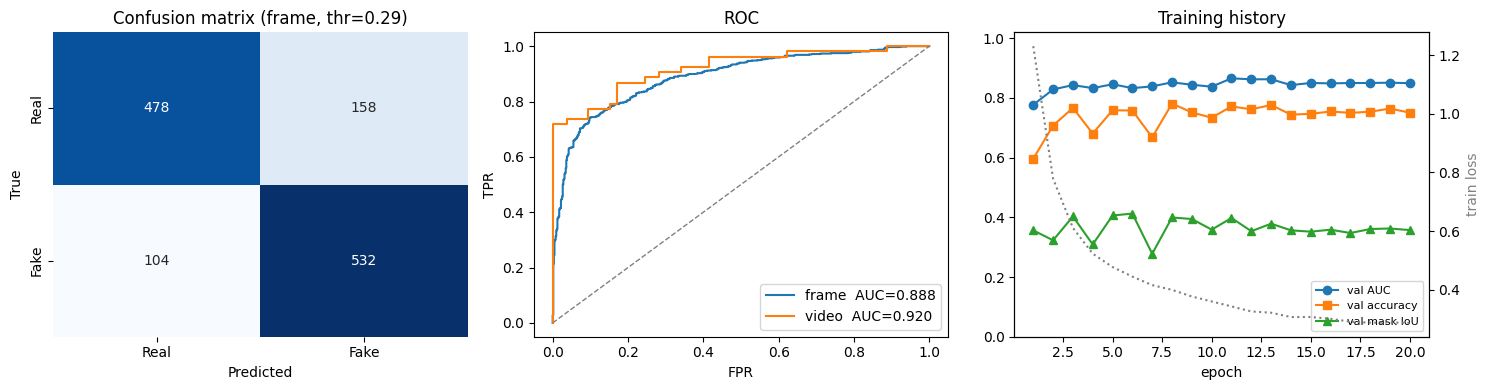

In [11]:
val_res = evaluate(model, val_dl, tta=True, collect_seg=True)
THR = tune_threshold(val_res["labels"], val_res["probs"])
MASK_THR = tune_mask_threshold(val_res["seg_pairs"])
print(f"Tuned on validation — classification threshold {THR:.2f} | mask threshold {MASK_THR:.2f}\n")

test_res = evaluate(model, test_dl, tta=True, mask_thr=MASK_THR)
frame_m = clf_metrics(test_res["labels"], test_res["probs"], THR)
vid_lab, vid_prob = to_video_level(test_df, test_res["probs"])
video_m = clf_metrics(vid_lab, vid_prob, THR)

summary = pd.DataFrame([
    {"level": "frame", "n": len(test_res["labels"]), **{k: v for k, v in frame_m.items() if k != "threshold"}},
    {"level": "video", "n": len(vid_lab),            **{k: v for k, v in video_m.items() if k != "threshold"}},
]).set_index("level")
print("CLASSIFICATION — held-out test split")
print(summary.round(4).to_string(), "\n")

print("SEGMENTATION — manipulated-region localisation")
print(f"  fakes scored           : {test_res['n_seg']}  (mask threshold {MASK_THR:.2f})")
print(f"  mean IoU               : {test_res['mean_iou']:.4f}")
print(f"  mean Dice              : {test_res['mean_dice']:.4f}")
print(f"  false mask area on REAL: {test_res['real_mask_coverage']:.2%}  "
      f"(should be near zero — a localiser that paints every face is useless)\n")

print(classification_report(test_res["labels"], (test_res["probs"] > THR).astype(int),
                            target_names=["real", "fake"], zero_division=0))

# ---------------------------------- plots ----------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cm = confusion_matrix(test_res["labels"], (test_res["probs"] > THR).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"], ax=axes[0])
axes[0].set_title(f"Confusion matrix (frame, thr={THR:.2f})")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

for lab, (y, p) in [("frame", (test_res["labels"], test_res["probs"])), ("video", (vid_lab, vid_prob))]:
    if len(np.unique(y)) > 1:
        fpr, tpr, _ = roc_curve(y, p)
        axes[1].plot(fpr, tpr, label=f"{lab}  AUC={roc_auc_score(y, p):.3f}")
axes[1].plot([0, 1], [0, 1], "--", c="gray", lw=1)
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("ROC"); axes[1].legend()

ep = range(1, len(history["train_loss"]) + 1)
axes[2].plot(ep, history["val_auc"], "o-", label="val AUC")
axes[2].plot(ep, history["val_acc"], "s-", label="val accuracy")
axes[2].plot(ep, history["val_iou"], "^-", label="val mask IoU")
ax2 = axes[2].twinx()
ax2.plot(ep, history["train_loss"], ":", c="gray", label="train loss")
ax2.set_ylabel("train loss", color="gray")
axes[2].set_xlabel("epoch"); axes[2].set_ylim(0, 1.02)
axes[2].set_title("Training history"); axes[2].legend(loc="lower right", fontsize=8)

fig.tight_layout(); fig.savefig(PLOT_DIR / "results.png", dpi=120); plt.show()

## 10. Segmentation output — what the model actually localises

Four columns per sample: the input crop, the pseudo ground-truth mask, the model's raw
manipulation-probability heatmap, and that heatmap thresholded and outlined on the face.

Real faces are included on purpose. A localisation head is only credible if it stays **quiet** on
unmanipulated input — a model that paints a hot region on every face has learned nothing about
*where*.

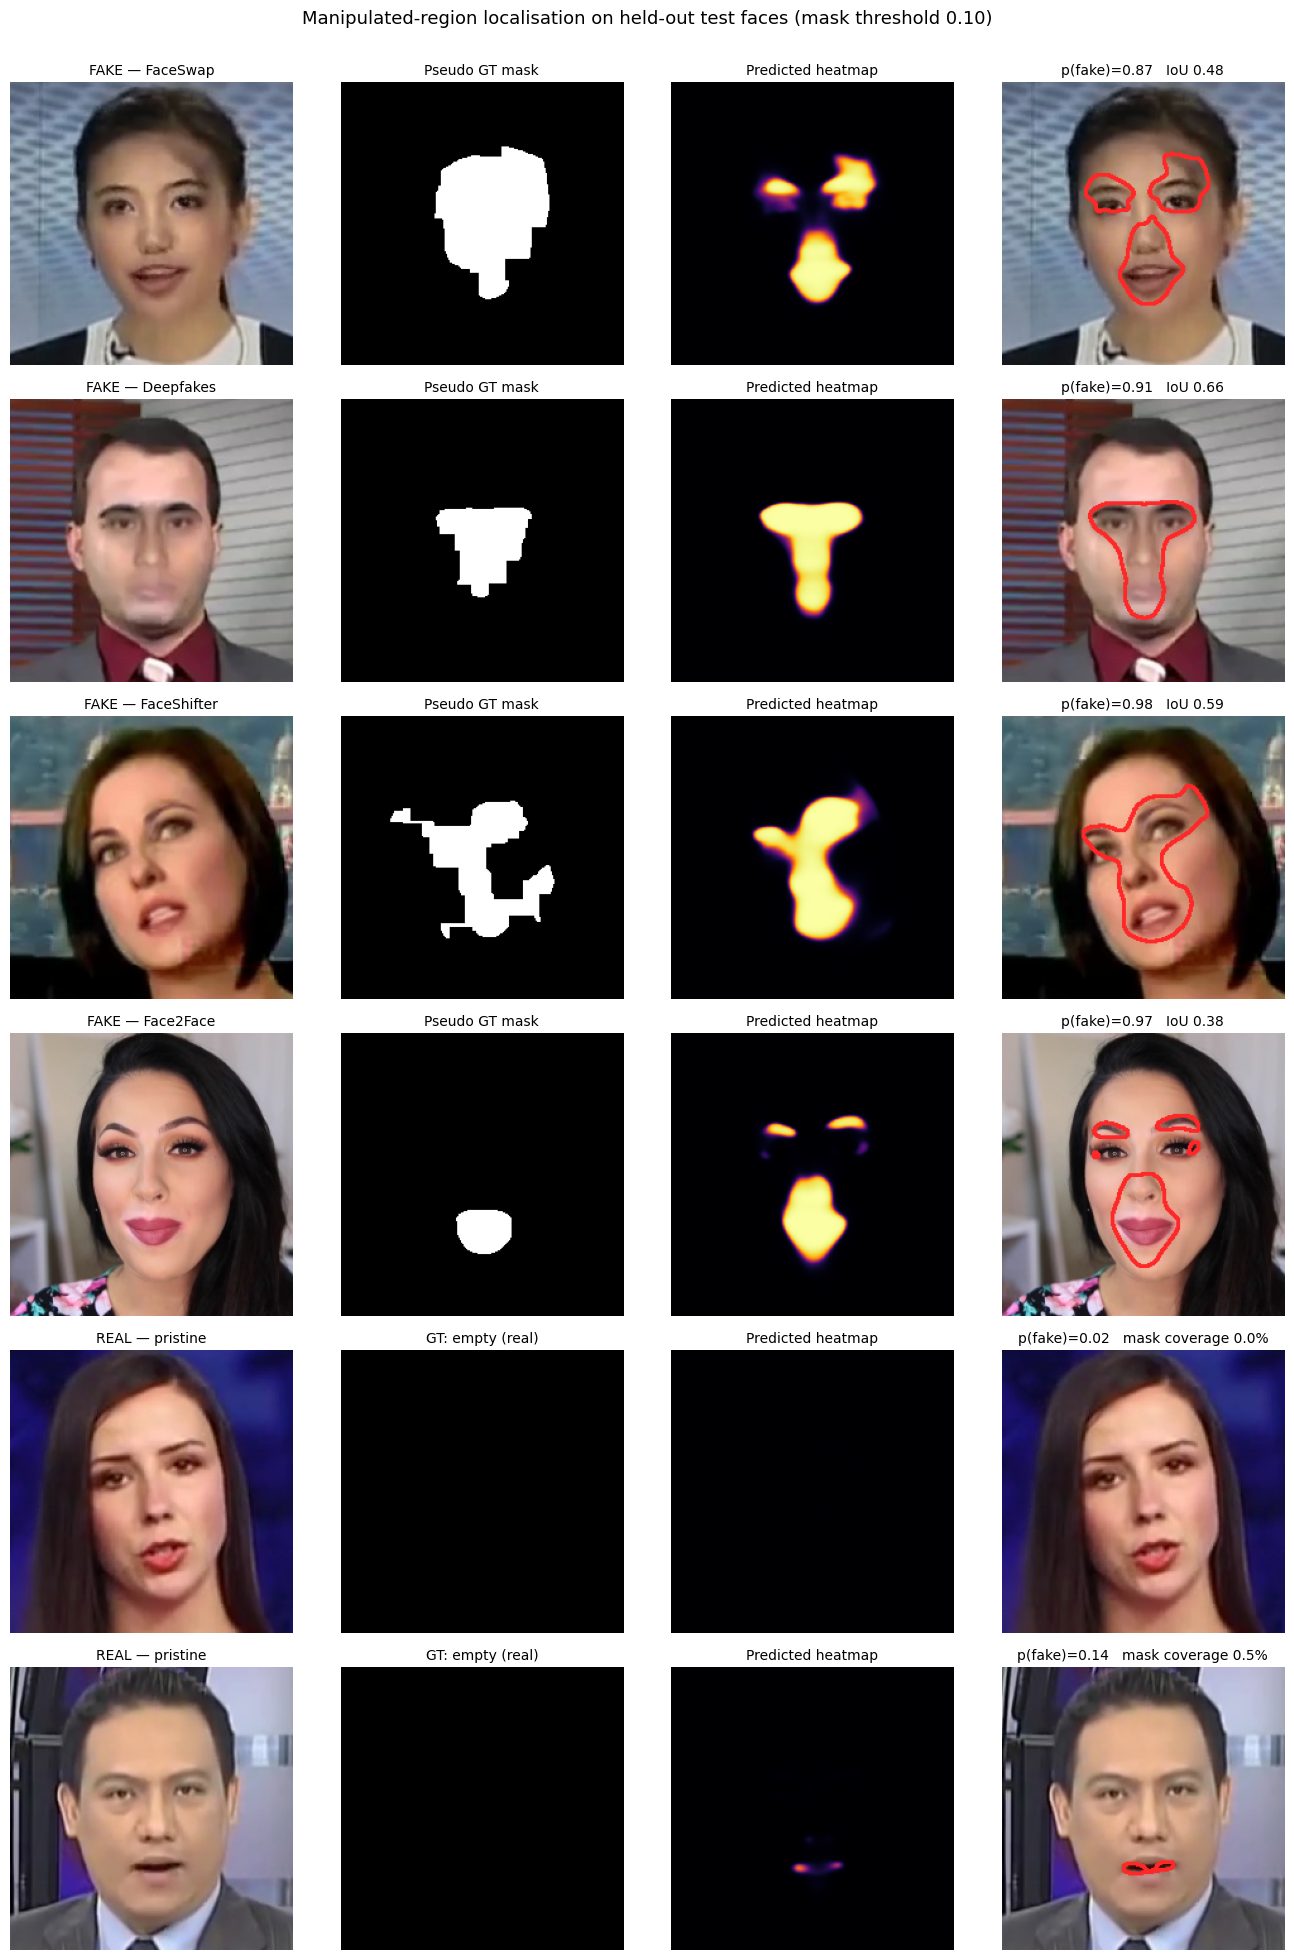

In [12]:
@torch.no_grad()
def show_segmentation(model, df, n_fake=4, n_real=2, mask_thr=0.5):
    model.eval()
    masked_fakes = df[(df.label == 1) & (df.seg_valid == 1)]
    reals = df[df.label == 0]
    pick = pd.concat([masked_fakes.sample(n=min(n_fake, len(masked_fakes)), random_state=SEED),
                      reals.sample(n=min(n_real, len(reals)), random_state=SEED)]).reset_index(drop=True)
    assert len(pick), "Nothing to visualise in this split."
    ds = FacedDataset(pick)

    fig, axes = plt.subplots(len(pick), 4, figsize=(13.5, 3.25 * len(pick)))
    axes = np.atleast_2d(axes)
    for i in range(len(pick)):
        img_t, label_t, mask_t, sv = ds[i]
        with amp_ctx():
            cls_logits, seg_logits = model(img_t.unsqueeze(0).to(DEVICE))
            c2, s2 = model(torch.flip(img_t.unsqueeze(0).to(DEVICE), dims=[3]))
        p_fake = torch.softmax(((cls_logits + c2) / 2).float(), 1)[0, 1].item()
        heat = torch.sigmoid(((seg_logits + torch.flip(s2, dims=[3])) / 2).float())[0, 0].cpu().numpy()

        rgb = cv2.cvtColor(cv2.imread(pick.iloc[i]["image_path"]), cv2.COLOR_BGR2RGB)
        gt = (mask_t[0].numpy() > 0.5).astype(np.uint8)
        pm = (heat > mask_thr).astype(np.uint8)

        overlay = rgb.copy()
        cnts, _ = cv2.findContours(pm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, cnts, -1, (255, 40, 40), 2)

        truth = "FAKE" if label_t.item() == 1 else "REAL"
        method = pick.iloc[i]["manipulation_method"] if label_t.item() == 1 else "pristine"
        iou_txt = f"IoU {iou_dice(pm, gt)[0]:.2f}" if sv.item() > 0.5 else \
                  f"mask coverage {pm.mean():.1%}"

        panels = [(rgb, f"{truth} — {method}", {}),
                  (gt * 255, "Pseudo GT mask" if sv.item() > 0.5 else "GT: empty (real)", {"cmap": "gray"}),
                  (heat, "Predicted heatmap", {"cmap": "inferno", "vmin": 0, "vmax": 1}),
                  (overlay, f"p(fake)={p_fake:.2f}   {iou_txt}", {})]
        for c, (im, ttl, kw) in enumerate(panels):
            axes[i, c].imshow(im, **kw); axes[i, c].set_title(ttl, fontsize=10); axes[i, c].axis("off")

    fig.suptitle(f"Manipulated-region localisation on held-out test faces "
                 f"(mask threshold {mask_thr:.2f})", y=1.003, fontsize=13)
    fig.tight_layout()
    return fig

fig = show_segmentation(model, test_df, mask_thr=MASK_THR)
fig.savefig(PLOT_DIR / "segmentation_examples.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Breakdown by manipulation method

Not every forgery is equally hard. Face-swapping methods (Deepfakes, FaceSwap, FaceShifter)
replace a large region and leave blending seams; expression-transfer methods (Face2Face,
NeuralTextures) change a small area subtly and are consistently harder to both detect and localise.
This table is usually the most informative single result in the review.

PER-MANIPULATION-METHOD PERFORMANCE (test split)
        method  fake crops  recall (fakes caught)  accuracy (vs. its reals)  mean p(fake)
   FaceShifter          96                 0.9896                    0.8750        0.8929
     Face2Face         156                 0.8910                    0.7981        0.8031
     Deepfakes         156                 0.8333                    0.7628        0.7549
      FaceSwap         168                 0.7738                    0.7917        0.6538
NeuralTextures          60                 0.6333                    0.7417        0.5188

Real crops — correctly identified: 0.7516


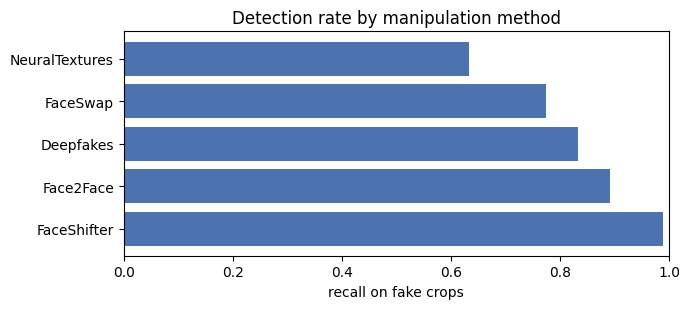

In [13]:
per = test_df.copy()
per["prob"] = test_res["probs"]
per["pred"] = (per["prob"] > THR).astype(int)

rows = []
for method, g in per[per.label == 1].groupby("manipulation_method"):
    reals = per[(per.label == 0) & (per.video_id.isin(g.video_id.unique()))]
    both = pd.concat([g, reals])
    rows.append({
        "method": method,
        "fake crops": len(g),
        "recall (fakes caught)": (g.pred == 1).mean(),
        "accuracy (vs. its reals)": (both.pred == both.label).mean(),
        "mean p(fake)": g["prob"].mean(),
    })

per_method = pd.DataFrame(rows).sort_values("recall (fakes caught)", ascending=False)
print("PER-MANIPULATION-METHOD PERFORMANCE (test split)")
print(per_method.round(4).to_string(index=False))
print(f"\nReal crops — correctly identified: {(per[per.label==0].pred == 0).mean():.4f}")

if len(per_method) > 1:
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.barh(per_method["method"], per_method["recall (fakes caught)"], color="#4C72B0")
    ax.set_xlim(0, 1); ax.set_xlabel("recall on fake crops")
    ax.set_title("Detection rate by manipulation method")
    fig.tight_layout(); fig.savefig(PLOT_DIR / "per_method.png", dpi=120); plt.show()

## 12. Save artifacts

In [14]:
torch.save({"state_dict": model.state_dict(), "image_size": IMAGE_SIZE,
            "cls_threshold": THR, "mask_threshold": MASK_THR,
            "arch": "MultiTaskNet(resnet18 encoder + unet seg decoder)"},
           CKPT_DIR / "final_model.pt")

run_summary = {
    "config": {"n_pairs": len(pairs), "frames_per_video": FRAMES_PER_VIDEO,
               "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
               "epochs_run": len(history["train_loss"]), "epochs_planned": EPOCHS,
               "lr_encoder": LR_ENCODER, "lr_head": LR_HEAD},
    "data": {"crops_total": len(frame_manifest), "train": len(train_df),
             "val": len(val_df), "test": len(test_df),
             "valid_masks": int(frame_manifest.seg_valid.sum())},
    "classification_frame": frame_m,
    "classification_video": video_m,
    "segmentation": {"mean_iou": test_res["mean_iou"], "mean_dice": test_res["mean_dice"],
                     "n_scored": test_res["n_seg"], "mask_threshold": MASK_THR,
                     "false_mask_area_on_real": test_res["real_mask_coverage"]},
    "best_val_auc": best_auc,
    "per_method": per_method.to_dict("records"),
    "total_runtime": hms(elapsed()),
}
with open(WORK_ROOT / "run_summary.json", "w") as f:
    json.dump(run_summary, f, indent=2, default=float)

print("=" * 64)
print("RUN SUMMARY")
print("=" * 64)
print(f"Crops              : {len(frame_manifest):,} at {IMAGE_SIZE}px "
      f"from {len(pairs)} video pairs")
print(f"Epochs completed   : {len(history['train_loss'])}/{EPOCHS}")
print(f"Frame  accuracy    : {frame_m['accuracy']:.4f}   AUC {frame_m['auc']:.4f}")
print(f"Video  accuracy    : {video_m['accuracy']:.4f}   AUC {video_m['auc']:.4f}")
print(f"Mask   IoU / Dice  : {test_res['mean_iou']:.4f} / {test_res['mean_dice']:.4f} "
      f"(thr {MASK_THR:.2f})")
print(f"False mask on real : {test_res['real_mask_coverage']:.2%}")
print(f"Total runtime      : {hms(elapsed())} of {hms(TOTAL_TIME_BUDGET_SEC)} budget")
print(f"\nSaved under {WORK_ROOT}:")
print("  checkpoints/best_model.pt, checkpoints/final_model.pt")
print("  plots/mask_provenance.png, plots/mask_area_hist.png, plots/results.png,")
print("  plots/segmentation_examples.png, plots/per_method.png")
print("  run_summary.json, frame_manifest.csv")

RUN SUMMARY
Crops              : 8,340 at 224px from 400 video pairs
Epochs completed   : 20/20
Frame  accuracy    : 0.7940   AUC 0.8881
Video  accuracy    : 0.8113   AUC 0.9195
Mask   IoU / Dice  : 0.4230 / 0.5557 (thr 0.10)
False mask on real : 2.45%
Total runtime      : 00:18:40 of 00:55:00 budget

Saved under /kaggle/working:
  checkpoints/best_model.pt, checkpoints/final_model.pt
  plots/mask_provenance.png, plots/mask_area_hist.png, plots/results.png,
  plots/segmentation_examples.png, plots/per_method.png
  run_summary.json, frame_manifest.csv
